# 1. Sequence preprocessing 

In [1]:
import pandas as pd
df_main = pd.read_csv('/group/diangelantonio/users/alessia_mapelli/Disease_network/main_sequence_09_07_2025.csv')
df_main = df_main[df_main['event_id'] != 25].copy()
df_mapping_main = pd.read_csv('/group/diangelantonio/users/alessia_mapelli/Disease_network/mapping_event_main_sequence_09_07_2025.csv')
df_mapping_main = df_mapping_main.iloc[:-1]


df_parallel = pd.read_csv('/group/diangelantonio/users/alessia_mapelli/Disease_network/parallel_sequence_09_07_2025.csv')
df_mapping_parallel  = pd.read_csv('/group/diangelantonio/users/alessia_mapelli/Disease_network/mapping_event_parallel_sequence_09_07_2025.csv')

In [9]:
print(df_main.shape)
print(df_parallel.shape)

(904979, 3)
(17588214, 3)


In [10]:
print(df_main.shape)
print(df_parallel.shape)

(904979, 3)
(17588214, 3)


In [11]:
df_parallel.head()

,f.eid,age_in_days_since_born,event_id
0,1000010.0,0,1
1,1000010.0,0,7
2,1000010.0,0,8
3,1000010.0,0,9
4,1000010.0,0,10


In [14]:
mask_pos = df_main['age_in_days_since_born'] == 0
df_main = df_main.loc[-mask_pos].copy()

In [15]:
mask_pos = df_main['age_in_days_since_born'] > 0
counts = df_main.loc[mask_pos].groupby('f.eid').size()
keep_ids = counts[counts > 2].index
print(len(keep_ids))
df_main = df_main[df_main['f.eid'].isin(keep_ids)].copy()
df_main.shape

113973


(544716, 3)

In [16]:
df_parallel = df_parallel[df_parallel['f.eid'].isin(keep_ids)].copy()
df_parallel.shape

(4726335, 3)

In [17]:
df_parallel = df_parallel[~(df_parallel['event_id'].isin([40,41,42, 59,60,61,43, 51, 57, 63, 64, 77, 78, 91, 92, 100, 109, 116]))].copy()

In [18]:
df_parallel.shape

(3285210, 3)

df_main shape: (544716, 3)
df_main columns: ['f.eid', 'age_in_days_since_born', 'event_id']

df_main – summary of 'age_in_days_since_born':
count    544716.000000
mean      23805.393912
std        3421.043273
min        8281.000000
25%       21555.000000
50%       24067.000000
75%       26420.000000
max       35951.000000
Name: age_in_days_since_born, dtype: float64



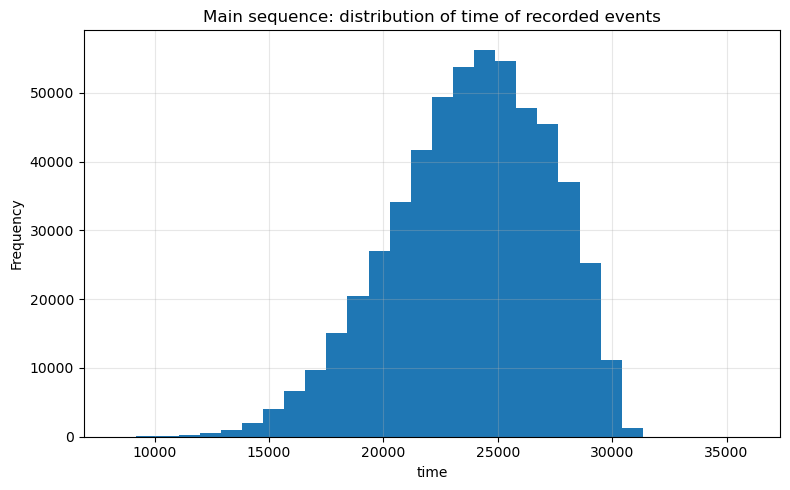

df_parallel shape: (3285210, 3)
df_parallel columns: ['f.eid', 'age_in_days_since_born', 'event_id']

df_parallel – summary of 'age_in_days_since_born':
count    3.285210e+06
mean     1.755303e+04
std      1.018709e+04
min      0.000000e+00
25%      1.551800e+04
50%      2.214800e+04
75%      2.455600e+04
max      3.595100e+04
Name: age_in_days_since_born, dtype: float64



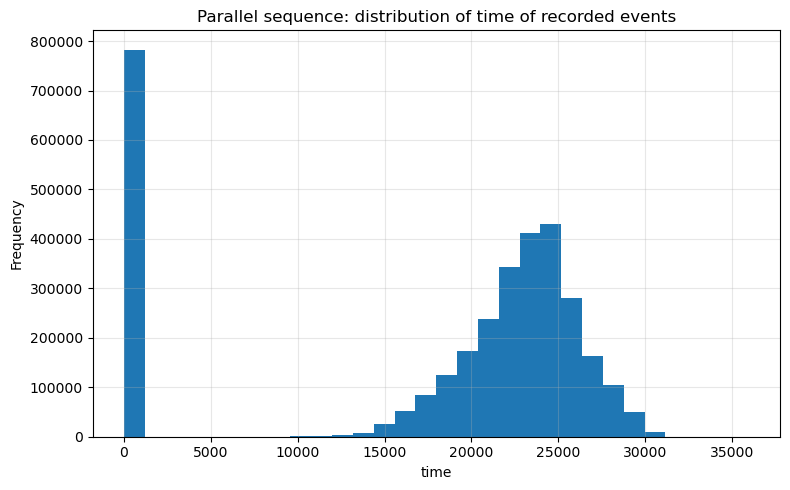

In [20]:
#Plot time event distributions
import matplotlib.pyplot as plt
import seaborn as sns
# Plot distribution
name = 'df_main'
print(f"{name} shape: {df_main.shape}")
print(f"{name} columns: {list(df_main.columns)}")
second_col = df_main.columns[1]
# Coerce to numeric if it's not already (non-numeric -> NaN)
s = pd.to_numeric(df_main[second_col], errors='coerce')
print(f"\n{name} – summary of '{second_col}':\n{s.describe()}\n")

# --- Histogram of the second column ---
plt.figure(figsize=(8, 5))
plt.hist(s.dropna(), bins=30)
plt.title(f"Main sequence: distribution of time of recorded events")
plt.xlabel("time")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("main_dist_time_events.png", format="png")
plt.show()

name = 'df_parallel'
print(f"{name} shape: {df_parallel.shape}")
print(f"{name} columns: {list(df_parallel.columns)}")
second_col = df_parallel.columns[1]
# Coerce to numeric if it's not already (non-numeric -> NaN)
s = pd.to_numeric(df_parallel[second_col], errors='coerce')
print(f"\n{name} – summary of '{second_col}':\n{s.describe()}\n")

# --- Histogram of the second column ---
plt.figure(figsize=(8, 5))
plt.hist(s.dropna(), bins=30)
plt.title(f"Parallel sequence: distribution of time of recorded events")
plt.xlabel("time")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("parall_dist_time_events.png", format="png")
plt.show()

In [21]:
# Map the disease names to the widely-used biomedical controlled vocabulary called Medical Subject Headings (MeSH) on which the pretrained model is based on
mesh_mapping_main = {
    "Acute Kidney Injury": "Acute Kidney Injury",
    "Acute Pulmonary Embolism": "Pulmonary Embolism",
    "Advanced Electrical Conduction System Delay (Pacemaker)": "Pacemaker, Artificial",
    "Aneurysm and dissection": "Aortic Aneurysm",
    "Aortic Valve Disorders": "Aortic Valve Stenosis",
    "Atrial Fibrillation or Flutter": "Atrial Fibrillation",
    "Cardiac Arrest": "Heart Arrest",
    "Cerebrovascular Disease": "Cerebrovascular Disorders",
    "Diabetes": "Diabetes Mellitus",
    "Dilated Cardiomyopathy": "Cardiomyopathy, Dilated",
    "Dyslipidemia": "Dyslipidemias",
    "End Stage Renal Disease": "Kidney Failure, Chronic, Endstage",
    "Endstage Heart Failure": "Heart Failure, Endstage",
    "Heart Failure": "Heart Failure",
    "Hemorrhagic Stroke": "Stroke, Hemorrhagic",
    "Hypertension": "Hypertension",
    "Ischemic Heart Disease": "Coronary Disease",
    "Mitral Valve Disorders": "Mitral Valve Insufficiency",
    "Other peripheral vascular diseases": "Peripheral Vascular Diseases",
    "Renal Function - CKD Stage 3": "Kidney Diseases, Chronic, Stage 3",
    "Renal Function - CKD Stage 4": "Kidney Diseases, Chronic, Stage 4",
    "Renal Function - CKD Stage 5": "Kidney Diseases, Chronic, Stage 5",
    "Tricuspid Valve Disorders": "Tricuspid Valve Insufficiency",
    "Ventricular Tachycardia": "Tachycardia, Ventricular",
    "Stroke": "Stroke",
}
df_mapping_main["type_event_MeSH"] = df_mapping_main["type_event"].map(mesh_mapping_main)

In [22]:
df_mapping_main.shape

(24, 7)

In [23]:
# Map the risk modifiers to the widely-used biomedical controlled vocabulary called Medical Subject Headings (MeSH) on which the pretrained model is based on
mesh_mapping_parallel = mesh_mapping = {
    "Sex_Female": "Female",
    "Sex_Male": "Male",
    "Ethnicity_Asian": "Ethnic, Asian",
    "Ethnicity_Black": "Ethnic, Black",
    "Ethnicity_Mixed": "Ethnic, Mixed",
    "Ethnicity_Other": "Ethnic, Other",
    "Ethnicity_White": "Ethnic, White",
    "mother_diabetes_disease": "History, Mother, Diabetes",
    "mother_heart_disease": "History, Mother, Heart Diseases",
    "mother_stroke_disease": "History, Mother, Stroke",
  "father_diabetes_disease": "History, Father, Diabetes",
    "father_heart_disease": "History, Father, Heart Diseases",
    "father_stroke_disease": "History, Father, Stroke",
   "siblings_diabetes_disease": "History, Siblings, Diabetes",
    "siblings_heart_disease": "History, Siblings, Heart Diseases",
    "siblings_stroke_disease": "History, Siblings, Stroke",
    "BMI_low": "Body Mass Index, low",
    "BMI_medium": "Body Mass Index, medium",
    "BMI_high": "Body Mass Index, high",
    "IMD_low": "Socioeconomic Factors, low",
    "IMD_middle": "Socioeconomic Factors, middle",
    "IMD_high": "Socioeconomic Factors, high",
    "Work_active": "Employment, active",
    "Work_inactive": "Employment, inactive",
    "Work_no": "Employment, no",
    "Edu_high": "Educational Status, high",
    "Edu_low": "Educational Status, low",
    "Edu_medium": "Educational Status, medium",
    "Married": "Marital Status",
    "Live_with_others": "Social Environment",
    "Smoking": "Smoking",
    "Smoking NO": "Smoking, no",
    "Alcoholic Cardiomyopathy": "Cardiomyopathy, Alcoholic",
    "Amyloidosis": "Amyloidosis",
    "Any solid tumor without metastasis": "Neoplasms",
    "Aplastic and other anemias and other bone marrow failure syndromes": "Anemia, Aplastic",
    "Arterial and capillary diseases": "Vascular Diseases",
    "Atherosclerosis": "Atherosclerosis",
    "Atrioventricular and left bundle-branch block": "Heart Block",
    "Bad control in diabetes": "Diabetes Mellitus",
    "Bad control in dyslipidemia": "Dyslipidemias",
    "Bad control in hypertension": "Hypertension",
    "BNP normal": "Natriuretic Peptide, Brain",
    "Bradycardia": "Bradycardia",
    "Cardiomyopathy Due to Drug and External Agent": "Cardiomyopathy, Drug-Induced",
    "Cardiomyopathy elsewhere": "Cardiomyopathies",
    "Chronic Obstructive Pulmonary Disease": "Pulmonary Disease, Chronic Obstructive",
    "Coagulation defects, purpura and other hemorrhagic conditions": "Purpura",
    "Congenital Malformations": "Congenital Abnormalities",
    "DBP high": "Blood Pressure, high",
    "DBP normal": "Blood Pressure, normal",
    "Deep vein thrombosis": "Venous Thrombosis",
    "Dysthyroidism": "Thyroid Diseases",
    "Endocardial Fibroelastosis": "Endocardial Fibroelastosis",
    "Endocarditis": "Endocarditis",
    "Endomyocardial (Eosinophilic) Disease": "Endomyocardial Fibrosis",
    "Fasting Glucose normal": "Blood Glucose, normal",
    "Fluid and electrolyte disorder": "Water-Electrolyte Imbalance",
    "Good control in diabetes": "Diabetes Mellitus",
    "Good control in dyslipidemia": "Dyslipidemias",
    "Good control in hypertension": "Hypertension",
    "Haemoglobin good": "Hemoglobins",
    "HbA1c normal": "Glycated Hemoglobin A, normal",
    "Heart rate normal": "Heart Rate, normal",
    "Hemiplegia or paraplegia": "Paraplegia",
    "Hemolytic anemias": "Anemia, Hemolytic",
    "High BNP or NT-proBNP": "Natriuretic Peptide, Brain, high",
    "High Lipoprotein a": "Lipoproteins, high",
    "High White Blood Cell Count": "Leukocyte Count, high",
    "HIV": "HIV Infections",
    "Hyperthyroidism": "Hyperthyroidism",
    "Hypertrophic Cardiomyopathy": "Cardiomyopathy, Hypertrophic",
    "Hypotension": "Hypotension",
    "Hypothyroidism": "Hypothyroidism",
    "Influenza": "Influenza, Human",
    "Intraoperative and postprocedural complications and disorders of circulatory system, not elsewhere classified": "Postoperative Complications",
    "LDL normal": "Lipoproteins, LDL, normal",
    "Lipoprotein A normal": "Lipoproteins, normal",
    "Liver disease": "Liver Diseases",
    "Low Platelet Count": "Thrombocytopenia",
    "Low White Blood Cell Count": "Leukopenia, low",
    "LVEF - Mid-range": "Ejection Fraction, middle",
    "LVEF - Preserved": "Ejection Fraction, preserved",
    "LVEF - Reduced": "Ejection Fraction,reduced",
    "Malignant neoplasms of lymphoid and hematopoietic": "Hematologic Neoplasms",
    "Mental, Behavioral and Neurodevelopmental disorders": "Mental Disorders",
    "Metastatic tumor": "Neoplasm Metastasis",
    "Mild Anemia": "Anemia",
    "Myocarditis": "Myocarditis",
    "Neurological disorders": "Nervous System Diseases",
    "Non-HDL normal": "Cholesterol, HDL, normal",
    "NT-proBNP normal": "Natriuretic Peptide, Brain, normal",
    "Nutritional anemias": "Anemia, Nutritional",
    "Obstructive syndrome (asthma or bronchiectasis)": "Pulmonary Disease, Obstructive",
    "Other conduction disorders": "Heart Conduction System",
    "Other heart disorders elsewhere": "Heart Diseases",
    "Other Restrictive Cardiomyopathy": "Cardiomyopathy, Restrictive",
    "Peptic ulcer disease": "Peptic Ulcer",
    "Pericarditis": "Pericarditis",
    "Platelet Count normal": "Platelet Count, normal",
    "Pneumonia": "Pneumonia",
    "Prediabetes": "Pre diabetic State",
    "Pregnancy related complications": "Pregnancy Complications",
    "Renal Function - CKD Stage 1": "Kidney Diseases, Chronic, stage 1",
    "Renal Function - CKD Stage 2": "Kidney Diseases, Chronic, stage 2",
    "Rheumatic disease": "Rheumatic Diseases",
    "Rheumatic heart disease": "Rheumatic Heart Disease",
    "SBP high": "Blood Pressure, high",
    "SBP normal": "Blood Pressure, normal",
    "Secondary hypertension": "Hypertension, Secondary",
    "Sepsis": "Sepsis",
    "Severe Anemia": "Anemia, severe",
    "Severe pulmonary condition": "Lung Diseases",
    "Tachycardia": "Tachycardia",
    "Urinary tract infection": "Urinary Tract Infections",
    "White Blood Cell Count normal": "Leukocyte Count, normal"
}

df_mapping_parallel["type_event_MeSH"] = df_mapping_parallel["type_event"].map(mesh_mapping_parallel)

In [24]:
df_mapping_parallel.shape

(116, 7)

In [25]:
# Group by patient and get token sequences translating them to MeSH disease terms
df_main['token'] = df_main['event_id'].astype(str)
df_mapping_main['event_id'] = df_mapping_main['event_id'].astype(str)
id_to_type = dict(zip(df_mapping_main['event_id'], df_mapping_main['type_event_MeSH']))
df_main['disease_name'] = df_main['token'].map(id_to_type)

In [26]:
df_main

,f.eid,age_in_days_since_born,event_id,token,disease_name
19,1000191.0,15223,9,9,Diabetes Mellitus
20,1000191.0,19206,16,16,Hypertension
21,1000191.0,19217,11,11,Dyslipidemias
25,1000239.0,20698,11,11,Dyslipidemias
26,1000239.0,20698,16,16,Hypertension
...,...,...,...,...,...
949473,6023717.0,18547,17,17,Coronary Disease
949474,6023717.0,19245,17,17,Coronary Disease
949475,6023717.0,20166,8,8,Cerebrovascular Disorders
949476,6023717.0,20581,8,8,Cerebrovascular Disorders


In [27]:
print(len(df_parallel['event_id'].dropna().unique()))

98


In [28]:
event_id_main = df_main['event_id'].dropna().unique()
print(len(event_id_main))

24


In [29]:
# Group by patient and get token sequences translating them to MeSH disease terms
df_parallel['token'] = df_parallel['event_id'].astype(str)
df_mapping_parallel['event_id'] = df_mapping_parallel['event_id'].astype(str)
id_to_type = dict(zip(df_mapping_parallel['event_id'], df_mapping_parallel['type_event_MeSH']))
df_parallel['disease_name'] = df_parallel['token'].map(id_to_type)
df_parallel

,f.eid,age_in_days_since_born,event_id,token,disease_name
621,1000191.0,0,2,2,Male
622,1000191.0,0,7,7,"Ethnic, White"
623,1000191.0,0,8,8,"History, Mother, Diabetes"
624,1000191.0,0,10,10,"History, Mother, Stroke"
625,1000191.0,0,11,11,"History, Father, Diabetes"
...,...,...,...,...,...
17588207,6023717.0,20373,105,105,"Kidney Diseases, Chronic, stage 2"
17588208,6023717.0,20373,108,108,"Blood Pressure, high"
17588211,6023717.0,21648,35,35,Neoplasms
17588212,6023717.0,21648,87,87,Neoplasm Metastasis


In [35]:
# Create sequences for comorbidity networks
df_comorb_network = df_main.copy()
df_comorb_network_order = df_comorb_network.sort_values(by=['f.eid', 'age_in_days_since_born'])
df_comorb_network_order

df_comorb_network_rf = pd.concat([df_parallel, df_main], axis=0, ignore_index=True)
df_comorb_network_rf_order = df_comorb_network_rf.sort_values(by=['f.eid', 'age_in_days_since_born'])
df_comorb_network_rf_order

,f.eid,age_in_days_since_born,event_id,token,disease_name
0,1000191.0,0,2,2,Male
1,1000191.0,0,7,7,"Ethnic, White"
2,1000191.0,0,8,8,"History, Mother, Diabetes"
3,1000191.0,0,10,10,"History, Mother, Stroke"
4,1000191.0,0,11,11,"History, Father, Diabetes"
...,...,...,...,...,...
3829924,6023717.0,20581,8,8,Cerebrovascular Disorders
3285207,6023717.0,21648,35,35,Neoplasms
3285208,6023717.0,21648,87,87,Neoplasm Metastasis
3285209,6023717.0,21910,101,101,Pneumonia


In [36]:
df_comorb_network_order.shape

(544716, 5)

In [34]:
df_comorb_network_rf_order.shape

(3829926, 5)

In [37]:
event_id_main = df_main['disease_name'].dropna().unique()
event_id_parall = df_parallel['disease_name'].dropna().unique()
print(len(event_id_parall))
print(len(event_id_main))

97
24


In [39]:
df_comorb_network_order.to_csv("sequence_main_final.csv", index=False)
df_comorb_network_rf_order.to_csv("sequence_main_parr_final.csv", index=False)

# 2. Cohort summary

In [1]:
import pandas as pd
df_main = pd.read_csv('sequence_main_final.csv')

In [2]:
data_unique = df_main.groupby(['f.eid', 'disease_name'], as_index=False).first()

n_tot_paz = df_main['f.eid'].nunique()

count = (
    data_unique
    .groupby('disease_name')
    .size()           # equivalente a count()
    .reset_index(name='count')
)

count['incidence'] = count['count'] / n_tot_paz
 
print(count)

                         disease_name   count  incidence
0                 Acute Kidney Injury   22572   0.198047
1                     Aortic Aneurysm    5596   0.049099
2               Aortic Valve Stenosis    8983   0.078817
3                 Atrial Fibrillation   34136   0.299510
4             Cardiomyopathy, Dilated    1594   0.013986
5           Cerebrovascular Disorders   21652   0.189975
6                    Coronary Disease   54631   0.479333
7                   Diabetes Mellitus   41326   0.362595
8                       Dyslipidemias   85736   0.752248
9                        Heart Arrest    3390   0.029744
10                      Heart Failure   19475   0.170874
11            Heart Failure, Endstage      37   0.000325
12                       Hypertension  109746   0.962912
13  Kidney Diseases, Chronic, Stage 3   19944   0.174989
14  Kidney Diseases, Chronic, Stage 4    2420   0.021233
15  Kidney Diseases, Chronic, Stage 5    1603   0.014065
16  Kidney Failure, Chronic, En